# Road Safety LLM: Fine-tuning Qwen2.5-1.5B on Indian Traffic Rules (SFT + QLoRA)

In this notebook we fine-tune the `Qwen/Qwen2.5-1.5B` base model so that it can answer simple **Indian traffic rules and road-safety questions**.

**Project summary**

- **Domain:** Road safety / Indian traffic rules
- **Dataset:** `Pravincoder/Indian_traffic_law_QA` (about 200 short English question-answer pairs)
- **Base model:** `Qwen/Qwen2.5-1.5B`
- **Method:** SFT (Supervised Fine-Tuning) with QLoRA (4-bit quantization + LoRA adapters)
- **Training:** exactly 1 epoch on a free Google Colab **Tesla T4** GPU
- **Evaluation:** evaluation loss, perplexity, base vs fine-tuned comparison, and an LLM judge (GPT-OSS 120B through Groq)
- **Demo:** a simple Gradio app

**Flow of this notebook**

```
Setup  →  Data  →  Model  →  Training  →  Evaluation  →  Demo
```

> Before you start: in Colab go to **Runtime → Change runtime type** and select **T4 GPU**.

# Check the GPU

In [1]:
!nvidia-smi

Tue Oct 27 09:12:52 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   45C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

# Install the libraries
Since we're using Unsloth, let's install the stack specifically for it:

In [2]:
!pip install -q -U unsloth

In [4]:
!pip install -q -U transformers datasets trl peft bitsandbytes accelerate evaluate

### Key Libraries for Fine-Tuning

Here is a quick overview of how the libraries we installed work together for our fine-tuning workflow:

*   **PyTorch (`torch`)**: The core deep-learning framework that handles tensor calculations and GPU execution.
*   **Transformers (`transformers`)**: Provides access to pre-trained architectures (like Qwen), tokenizers, and model configurations.
*   **Datasets (`datasets`)**: Simplifies downloading, loading, and pre-processing datasets (like `Indian_traffic_law_QA`) from Hugging Face.
*   **PEFT (`peft`)**: Implements Parameter-Efficient Fine-Tuning. It allows us to train small, specialized adapters (LoRA) instead of updating billions of parameters.
*   **TRL (`trl`)**: Provides high-level training API utilities like `SFTTrainer` (Supervised Fine-Tuning Trainer) to manage the main training loop easily.
*   **bitsandbytes (`bitsandbytes`)**: Enables memory-efficient operations and 4-bit/8-bit quantization (QLoRA) to let large models fit on limited GPU memory.
*   **Unsloth (`unsloth`)**: An optimization layer built on top of the PyTorch and Hugging Face ecosystem that speeds up training and reduces GPU memory footprint.

---

# Verify everything

In [5]:
import unsloth
import torch
import transformers
import datasets
import peft
import trl
import bitsandbytes

print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("Datasets:", datasets.__version__)
print("PEFT:", peft.__version__)
print("TRL:", trl.__version__)
print("Unsloth:", unsloth.__version__)

🦥 Unsloth: Will patch your computer to enable 2x faster free finetuning.


/usr/local/lib/python3.13/dist-packages/transformers/configuration_utils.py:720: FutureWarning: `rope_scaling` is deprecated and will be removed in a future version. Set `rope_parameters` instead, with `rope_type` and `rope_theta` included.
  warnings.warn(


Unsloth: xformers is installed but cannot load with torch 2.11.0+cu130 (it was built for 2.10.0+cu128), so PyTorch attention is used instead.
To install a matching xformers, run `unsloth install-kernels xformers`, or `pip uninstall xformers` to hide this. UNSLOTH_ENABLE_LOGGING=1 shows the full error.
🦥 Unsloth Zoo will now patch everything to make training faster!
PyTorch: 2.11.0+cu130
Transformers: 5.21.0
Datasets: 5.1.0
PEFT: 0.21.2
TRL: 1.16.0
Unsloth: 2026.10.9


In [6]:
print("\nCUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "GPU memory:",
        round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2),
        "GB"
    )


CUDA available: True
GPU: Tesla T4
GPU memory: 14.56 GB


# Load the Road Safety dataset

In [7]:
from datasets import load_dataset

dataset = load_dataset("Pravincoder/Indian_traffic_law_QA")

README.md:   0%|          | 0.00/373 [00:00<?, ?B/s]

Indian_Traffic_Rules_final.csv:   0%|          | 0.00/38.8k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/200 [00:00<?, ? examples/s]

In [8]:
print(dataset)

DatasetDict({
    train: Dataset({
        features: ['text'],
        num_rows: 200
    })
})


In [9]:
print(dataset["train"].column_names)

# We do NOT assume any column names. If the dataset does not look like we expect, stop here.
assert "text" in dataset["train"].column_names, (
    "Expected a 'text' column. Found: " + str(dataset["train"].column_names)
)

['text']


In [10]:
example = dataset["train"][0]

for column, value in example.items():
    print(f"\n{'=' * 20} {column} {'=' * 20}")
    print(value)


==================== text ====================
###Human:
What is the speed limit in residential areas in India? 

###Assistant:
The speed limit in residential areas in India is usually 20-40 km/h, but it can vary by location.


# Inspect a random sample

In [11]:
sample = dataset["train"].shuffle(seed=42).select(range(5))

for i, row in enumerate(sample):
    print(f"\n{'#' * 60}")
    print(f"RANDOM EXAMPLE {i}")
    print(f"{'#' * 60}")
    print(row["text"])


############################################################
RANDOM EXAMPLE 0
############################################################
###Human:
What is the speed limit for trucks on national highways in India? 

###Assistant:
The speed limit for trucks on national highways in India varies but is often around 60-70 km/h.

############################################################
RANDOM EXAMPLE 1
############################################################
###Human:
What does a white arrow on the road indicate? 

###Assistant:
A white arrow on the road indicates the direction of traffic flow.

############################################################
RANDOM EXAMPLE 2
############################################################
###Human:
Explain Section 66 of the Motor Vehicles Act, 1988. 

###Assistant:
Section 66 of the Motor Vehicles Act, 1988 deals with the suspension and cancellation of licenses.

############################################################
RANDOM EXAMPLE

### What we learned about the dataset

This dataset is **different from the finance dataset**:

- It has only **one column**, called `text`.
- Each row already contains the question **and** the answer in one string.
- The question starts after `###Human:` and the answer starts after `###Assistant:`.

So we cannot directly use separate `instruction` and `response` columns. First we need to **split the `text` column into a question and an answer**.

```
###Human: <question> ###Assistant: <answer>
        │                         │
        ▼                         ▼
   instruction                 response
```

# Create our clean dataset

Split `text` into `instruction` (model input) and `response` (model target/output).
Rows that do not match the `###Human: ... ###Assistant: ...` pattern are removed.

In [12]:
import re

raw_dataset = dataset["train"]

pattern = re.compile(
    r"^\s*###\s*Human:\s*(.*?)\s*###\s*Assistant:\s*(.*?)\s*$",
    flags=re.DOTALL | re.IGNORECASE
)

def clean_text(value):
    # remove extra spaces and new lines
    return re.sub(r"\s+", " ", value).strip()

def split_human_assistant(example):
    match = pattern.match(example["text"])

    if match is None:
        return {"instruction": None, "response": None}

    return {
        "instruction": clean_text(match.group(1)),
        "response": clean_text(match.group(2)),
    }

parsed_dataset = raw_dataset.map(split_human_assistant)
print("Rows before parsing:", len(parsed_dataset))

# keep only rows where both parts were found and are not empty
parsed_dataset = parsed_dataset.filter(
    lambda ex: ex["instruction"] is not None
    and ex["response"] is not None
    and len(ex["instruction"]) > 0
    and len(ex["response"]) > 0
)
print("Rows after parsing :", len(parsed_dataset))

assert len(parsed_dataset) > 0, "Parsing failed for every row. Check the text format above."

# check that no marker was left inside the question or the answer
leftover = sum(
    ("###" in ex["instruction"]) or ("###" in ex["response"])
    for ex in parsed_dataset
)
print("Rows with leftover ### markers:", leftover)

Map:   0%|          | 0/200 [00:00<?, ? examples/s]

Rows before parsing: 200


Filter:   0%|          | 0/200 [00:00<?, ? examples/s]

Rows after parsing : 200
Rows with leftover ### markers: 0


In [13]:
for i in range(3):
    print(f"\nExample {i}")
    print("INSTRUCTION:", parsed_dataset[i]["instruction"])
    print("RESPONSE   :", parsed_dataset[i]["response"])


Example 0
INSTRUCTION: What is the speed limit in residential areas in India?
RESPONSE   : The speed limit in residential areas in India is usually 20-40 km/h, but it can vary by location.

Example 1
INSTRUCTION: When should you use hazard lights on your vehicle?
RESPONSE   : Hazard lights should only be used in the case of a vehicle breakdown or to indicate a temporary obstruction on the road.

Example 2
INSTRUCTION: What is the penalty for not wearing a helmet while riding a two-wheeler?
RESPONSE   : The penalty for not wearing a helmet while riding a two-wheeler in India can vary by state, but it often includes fines and points on your driving license.


Remove exact duplicate question-answer pairs.
If the **same question** appears with a **different answer**, we keep both (we do not invent or choose answers), but we print how often it happens.

In [14]:
from datasets import Dataset
from collections import Counter

rows_before = len(parsed_dataset)

df = parsed_dataset.to_pandas()[["instruction", "response"]]
df = df.drop_duplicates().reset_index(drop=True)

# Keep only the columns needed for our SFT dataset
sft_dataset = Dataset.from_pandas(df, preserve_index=False)

print("Rows before removing duplicates:", rows_before)
print("Rows after removing duplicates :", len(sft_dataset))
print("Exact duplicates removed       :", rows_before - len(sft_dataset))

question_counts = Counter(sft_dataset["instruction"])
repeated_questions = {q: c for q, c in question_counts.items() if c > 1}

print("\nQuestions that appear more than once:", len(repeated_questions))
for q, c in list(repeated_questions.items())[:5]:
    print(f"  ({c}x) {q}")

print()
print(sft_dataset)
print(sft_dataset.column_names)

Rows before removing duplicates: 200
Rows after removing duplicates : 162
Exact duplicates removed       : 38

Questions that appear more than once: 2
  (2x) What is the penalty for driving without a valid license?
  (2x) What does a rectangular traffic sign with a blue border indicate?

Dataset({
    features: ['instruction', 'response'],
    num_rows: 162
})
['instruction', 'response']


Check the type of questions in the dataset

In [15]:
question_starts = Counter(
    " ".join(q.split()[:3]) for q in sft_dataset["instruction"]
)

for start, count in question_starts.most_common(10):
    print(f"{start}: {count}")

What is the: 104
What does a: 18
What should you: 17
What are the: 7
When should you: 4
What does the: 1
Explain Section 129: 1
Explain Section 184: 1
Explain Section 177: 1
Explain Section 66: 1


This dataset is small (only about 200 examples), so we will **not** select a smaller random subset like we did for a large dataset. The clean approach is:
1. Shuffle all the clean examples.
2. Use a fixed seed so our selection is reproducible.
3. Split all of them into train/validation/evaluation.

Nothing is added or invented. We only use the examples that are already in the dataset.

---

## Shuffle the full dataset

In [16]:
# Shuffle the dataset reproducibly
shuffled_dataset = sft_dataset.shuffle(seed=42)

print(shuffled_dataset)
print("Total examples:", len(shuffled_dataset))

Dataset({
    features: ['instruction', 'response'],
    num_rows: 162
})
Total examples: 162


## Split into Train / Validation / Evaluation

With only about 200 examples, a 90/5/5 split would leave just about 10 examples for validation and evaluation, which is too small. So we use **80% train / 10% validation / 10% evaluation**.

In [17]:
# Split 80% train, 20% temporary
train_test = shuffled_dataset.train_test_split(
    test_size=0.20,
    seed=42
)

# Split the temporary 20% equally into validation and evaluation
val_eval = train_test["test"].train_test_split(
    test_size=0.50,
    seed=42
)

train_dataset = train_test["train"]
val_dataset = val_eval["train"]
eval_dataset = val_eval["test"]

print("Train:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Evaluation:", len(eval_dataset))

Train: 129
Validation: 16
Evaluation: 17


Because the dataset contains some repeated questions, let's check how many validation/evaluation questions also appear in the training set.
This is only a check. If the number is not zero, the evaluation score can look a little better than it would on completely new questions.

In [18]:
train_questions = set(train_dataset["instruction"])

val_overlap = sum(q in train_questions for q in val_dataset["instruction"])
eval_overlap = sum(q in train_questions for q in eval_dataset["instruction"])

print("Validation questions that also appear in train:", val_overlap, "/", len(val_dataset))
print("Evaluation questions that also appear in train:", eval_overlap, "/", len(eval_dataset))

Validation questions that also appear in train: 0 / 16
Evaluation questions that also appear in train: 1 / 17


In [19]:
from google.colab import drive
import os

drive.mount("/content/drive")

project_path = "/content/drive/MyDrive/road_safety_qwen2.5_1.5b_qlora"
base_path = f"{project_path}/indian-traffic-law"
os.makedirs(base_path, exist_ok=True)

train_dataset.save_to_disk(f"{base_path}/train")
val_dataset.save_to_disk(f"{base_path}/validation")
eval_dataset.save_to_disk(f"{base_path}/evaluation")

print("Datasets saved successfully!")
print(base_path)

Mounted at /content/drive


Saving the dataset (0/1 shards):   0%|          | 0/129 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/16 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/17 [00:00<?, ? examples/s]

Datasets saved successfully!
/content/drive/MyDrive/road_safety_qwen2.5_1.5b_qlora/indian-traffic-law


In [20]:
from datasets import load_from_disk

project_path = "/content/drive/MyDrive/road_safety_qwen2.5_1.5b_qlora"
base_path = f"{project_path}/indian-traffic-law"

train_dataset = load_from_disk(f"{base_path}/train")
val_dataset = load_from_disk(f"{base_path}/validation")
eval_dataset = load_from_disk(f"{base_path}/evaluation")

print("Train:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Evaluation:", len(eval_dataset))

Train: 129
Validation: 16
Evaluation: 17


---

## Load the Qwen tokenizer

In [21]:
from transformers import AutoTokenizer

model_name = "Qwen/Qwen2.5-1.5B"

tokenizer = AutoTokenizer.from_pretrained(model_name)

print("Tokenizer loaded")
print("Chat template available:", tokenizer.chat_template is not None)

config.json:   0%|          | 0.00/684 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.23k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

Tokenizer loaded
Chat template available: True


Format the dataset using the instruction → user message and response → assistant message.

First let's see what the default Qwen chat template does:

In [22]:
demo_messages = [
    {"role": "user", "content": train_dataset[0]["instruction"]},
    {"role": "assistant", "content": train_dataset[0]["response"]},
]

print(tokenizer.apply_chat_template(demo_messages, tokenize=False))

<|im_start|>system
You are a helpful assistant.<|im_end|>
<|im_start|>user
Explain Section 177B of the Motor Vehicles Act, 1988.<|im_end|>
<|im_start|>assistant
Section 177B of the Motor Vehicles Act, 1988 deals with the power to regulate the use of sirens and horns.<|im_end|>



The default Qwen chat template usually adds a **system message** by itself (look at the start of the output above).
We don't want that extra text in our training data, so we write the Qwen chat format by hand:

```
<|im_start|>user
{question}<|im_end|>
<|im_start|>assistant
{answer}<|im_end|>
```

We keep the "question part" in a small function called `format_prompt`, so we can use **exactly the same format** later when we test the model.

In [23]:
def format_prompt(question):
    # what the model sees BEFORE it writes the answer
    return (
        "<|im_start|>user\n"
        f"{question}"
        "<|im_end|>\n"
        "<|im_start|>assistant\n"
    )


def format_chat(example):
    text = format_prompt(example["instruction"]) + f"{example['response']}<|im_end|>"
    return {"text": text}


train_dataset = train_dataset.map(format_chat)
val_dataset = val_dataset.map(format_chat)
eval_dataset = eval_dataset.map(format_chat)

print(train_dataset[0]["text"])

Map:   0%|          | 0/129 [00:00<?, ? examples/s]

Map:   0%|          | 0/16 [00:00<?, ? examples/s]

Map:   0%|          | 0/17 [00:00<?, ? examples/s]

<|im_start|>user
Explain Section 177B of the Motor Vehicles Act, 1988.<|im_end|>
<|im_start|>assistant
Section 177B of the Motor Vehicles Act, 1988 deals with the power to regulate the use of sirens and horns.<|im_end|>


This creates a new text field containing the actual Qwen-formatted conversation that SFT will train on.

In [24]:
print(train_dataset)

Dataset({
    features: ['instruction', 'response', 'text'],
    num_rows: 129
})


## remove the metadata columns

In [25]:
train_dataset = train_dataset.select_columns(["text"])
val_dataset = val_dataset.select_columns(["text"])
eval_dataset = eval_dataset.select_columns(["text"])

print("Train columns:", train_dataset.column_names)
print("Validation columns:", val_dataset.column_names)
print("Evaluation columns:", eval_dataset.column_names)

Train columns: ['text']
Validation columns: ['text']
Evaluation columns: ['text']


save the formatted datasets back to Drive.

In [26]:
from datasets import DatasetDict

formatted_path = f"{project_path}/indian-traffic-law-formatted"

formatted_dataset = DatasetDict({
    "train": train_dataset,
    "validation": val_dataset,
    "evaluation": eval_dataset
})

formatted_dataset.save_to_disk(formatted_path)

print("Formatted datasets saved successfully!")
print(formatted_path)

Saving the dataset (0/1 shards):   0%|          | 0/129 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/16 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/17 [00:00<?, ? examples/s]

Formatted datasets saved successfully!
/content/drive/MyDrive/road_safety_qwen2.5_1.5b_qlora/indian-traffic-law-formatted


---

---

## Reload the formatted dataset from Drive

In [27]:
from datasets import load_from_disk

project_path = "/content/drive/MyDrive/road_safety_qwen2.5_1.5b_qlora"
formatted_path = f"{project_path}/indian-traffic-law-formatted"

formatted_dataset = load_from_disk(formatted_path)

train_dataset = formatted_dataset["train"]
val_dataset = formatted_dataset["validation"]
eval_dataset = formatted_dataset["evaluation"]

print("Train:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Evaluation:", len(eval_dataset))
print("Columns:", train_dataset.column_names)

Train: 129
Validation: 16
Evaluation: 17
Columns: ['text']


# Check the sequence lengths
Before tokenizing, let's check how long our examples really are (without truncation). The road-safety answers are short, so we expect them to be much shorter than the finance examples.

In [28]:
import numpy as np

def get_lengths(dataset_split):
    return [
        len(tokenizer(example["text"], truncation=False)["input_ids"])
        for example in dataset_split
    ]

train_lengths = get_lengths(train_dataset)
val_lengths = get_lengths(val_dataset)
eval_lengths = get_lengths(eval_dataset)

all_lengths = train_lengths + val_lengths + eval_lengths

print("Minimum:", min(all_lengths))
print("Maximum:", max(all_lengths))
print("Mean:", round(np.mean(all_lengths), 2))
print("95th percentile:", int(np.percentile(all_lengths, 95)))

for limit in [64, 96, 128, 256]:
    count = sum(length > limit for length in all_lengths)
    print(f"Examples exceeding {limit} tokens: {count} "
          f"({round(count / len(all_lengths) * 100, 2)} %)")

Minimum: 29
Maximum: 63
Mean: 44.75
95th percentile: 56
Examples exceeding 64 tokens: 0 (0.0 %)
Examples exceeding 96 tokens: 0 (0.0 %)
Examples exceeding 128 tokens: 0 (0.0 %)
Examples exceeding 256 tokens: 0 (0.0 %)


### Tokenization & Analysis

- We analyzed the original text lengths **without truncation**.
- The dataset is made of very short question-answer pairs, so a long limit like 768 tokens is not needed.
- We choose `max_length` = the longest example, rounded up to the next multiple of 32. This way **no example is truncated** and we do not waste memory.

In [29]:
max_length = int(np.ceil(max(all_lengths) / 32) * 32)

def tokenize_dataset(example):
    return tokenizer(
        example["text"],
        truncation=True,
        max_length=max_length,
    )

tokenized_train = train_dataset.map(
    tokenize_dataset,
    batched=True,
    remove_columns=["text"]
)

tokenized_val = val_dataset.map(
    tokenize_dataset,
    batched=True,
    remove_columns=["text"]
)

tokenized_eval = eval_dataset.map(
    tokenize_dataset,
    batched=True,
    remove_columns=["text"]
)

print("Train:", len(tokenized_train))
print("Validation:", len(tokenized_val))
print("Evaluation:", len(tokenized_eval))
print("Max length:", max_length)

Map:   0%|          | 0/129 [00:00<?, ? examples/s]

Map:   0%|          | 0/16 [00:00<?, ? examples/s]

Map:   0%|          | 0/17 [00:00<?, ? examples/s]

Train: 129
Validation: 16
Evaluation: 17
Max length: 64


In [30]:
# inspect the tokenized data before we save it.

print("Columns:", tokenized_train.column_names)
print("Number of tokens:", len(tokenized_train[0]["input_ids"]))

print("\nFirst 30 token IDs:")
print(tokenized_train[0]["input_ids"][:30])

print("\nFirst 30 tokens:")
print(tokenizer.convert_ids_to_tokens(
    tokenized_train[0]["input_ids"][:30]
))

print("\nLast 5 tokens:")
print(tokenizer.convert_ids_to_tokens(
    tokenized_train[0]["input_ids"][-5:]
))

Columns: ['input_ids', 'attention_mask']
Number of tokens: 60

First 30 token IDs:
[151644, 872, 198, 840, 20772, 11113, 220, 16, 22, 22, 33, 315, 279, 17614, 55020, 3218, 11, 220, 16, 24, 23, 23, 13, 151645, 198, 151644, 77091, 198, 9620, 220]

First 30 tokens:
['<|im_start|>', 'user', 'Ċ', 'Ex', 'plain', 'ĠSection', 'Ġ', '1', '7', '7', 'B', 'Ġof', 'Ġthe', 'ĠMotor', 'ĠVehicles', 'ĠAct', ',', 'Ġ', '1', '9', '8', '8', '.', '<|im_end|>', 'Ċ', '<|im_start|>', 'assistant', 'Ċ', 'Section', 'Ġ']

Last 5 tokens:
['ns', 'Ġand', 'Ġhorns', '.', '<|im_end|>']


## save the tokenized datasets to Drive

In [31]:
from datasets import DatasetDict

tokenized_path = f"{project_path}/indian-traffic-law-tokenized"

tokenized_dataset = DatasetDict({
    "train": tokenized_train,
    "validation": tokenized_val,
    "evaluation": tokenized_eval
})

tokenized_dataset.save_to_disk(tokenized_path)

print("Tokenized datasets saved successfully!")
print(tokenized_path)

Saving the dataset (0/1 shards):   0%|          | 0/129 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/16 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/17 [00:00<?, ? examples/s]

Tokenized datasets saved successfully!
/content/drive/MyDrive/road_safety_qwen2.5_1.5b_qlora/indian-traffic-law-tokenized


In [32]:
from datasets import load_from_disk

project_path = "/content/drive/MyDrive/road_safety_qwen2.5_1.5b_qlora"
tokenized_path = f"{project_path}/indian-traffic-law-tokenized"

tokenized_dataset = load_from_disk(tokenized_path)

tokenized_train = tokenized_dataset["train"]
tokenized_val = tokenized_dataset["validation"]
tokenized_eval = tokenized_dataset["evaluation"]

# longest tokenized example (used later as max_length for the trainer)
max_length = max(
    len(ids)
    for split in [tokenized_train, tokenized_val, tokenized_eval]
    for ids in split["input_ids"]
)

print("Train:", len(tokenized_train))
print("Validation:", len(tokenized_val))
print("Evaluation:", len(tokenized_eval))
print("Columns:", tokenized_train.column_names)
print("Max length:", max_length)

Train: 129
Validation: 16
Evaluation: 17
Columns: ['input_ids', 'attention_mask']
Max length: 63


# Model setup
We will load Qwen/Qwen2.5-1.5B base model in 4-bit. This is the first part of QLoRA.



```
Qwen2.5-1.5B
     ↓
Load pretrained base weights
     ↓
4-bit NF4 quantization
     ↓
Model loaded into GPU memory
```

In [33]:
from transformers import AutoModelForCausalLM, BitsAndBytesConfig
import torch

model_name = "Qwen/Qwen2.5-1.5B"

bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.float16,
    bnb_4bit_use_double_quant=True
)

model = AutoModelForCausalLM.from_pretrained(
    model_name,
    quantization_config=bnb_config,
    device_map="auto",
    dtype=torch.float16
)

print("Model loaded successfully")
print("Model dtype:", model.dtype)

model.safetensors: reconstructing file:   0%|          |  0.00B / 3.09GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/138 [00:00<?, ?B/s]

Model loaded successfully
Model dtype: torch.float16


## prepare the model for QLoRA
Before adding LoRA adapters, we need to prepare the quantized model for k-bit training. This handles things such as making the appropriate layers trainable and preparing the model for gradient computation.

In [34]:
from peft import prepare_model_for_kbit_training

model = prepare_model_for_kbit_training(model)

print("Model prepared for QLoRA training")

Model prepared for QLoRA training


# Add the LoRA adapters.
This is the part that turns our setup from:
4-bit quantized model

into:
QLoRA

The base Qwen model stays frozen, and we add small trainable LoRA matrices.



```
Self-Attention
 ├── Q projection → q_proj  ← LoRA
 ├── K projection → k_proj  ← LoRA
 ├── V projection → v_proj  ← LoRA
 └── Output projection → o_proj ← LoRA

MLP
 ├── gate_proj ← LoRA
 ├── up_proj   ← LoRA
 └── down_proj ← LoRA
```

In [35]:
from peft import LoraConfig, get_peft_model

lora_config = LoraConfig(
    r=16,
    lora_alpha=32,
    lora_dropout=0.05,
    bias="none",
    task_type="CAUSAL_LM",
    target_modules=[
        "q_proj",
        "k_proj",
        "v_proj",
        "o_proj",
        "gate_proj",
        "up_proj",
        "down_proj"
    ]
)

model = get_peft_model(model, lora_config)

model.print_trainable_parameters()

trainable params: 18,464,768 || all params: 1,562,179,072 || trainable%: 1.1820


# Configure the SFT trainer
Before training, we'll configure:
- training dataset
- validation dataset
- tokenizer
- sequence length
- batch size
- gradient accumulation
- learning rate
- 1 epoch
- FP16
- gradient checkpointing
- checkpoint saving

**Note:** our road-safety training set is small (about 160 examples). If we kept `gradient_accumulation_steps=16`, the model would get only about 10 weight updates in one epoch. So we use `gradient_accumulation_steps=4` (about 40 updates), and we log / evaluate / save more often. Everything else stays the same as our earlier QLoRA setup.

In [43]:
from trl import SFTConfig

training_args = SFTConfig(
    output_dir=f"{project_path}/checkpoints",

    num_train_epochs=5,

    per_device_train_batch_size=1,
    per_device_eval_batch_size=1,
    gradient_accumulation_steps=4,

    learning_rate=2e-4,
    warmup_steps=5,

    fp16=True,
    gradient_checkpointing=True,

    logging_steps=5,

    eval_strategy="steps",
    eval_steps=10,

    save_strategy="steps",
    save_steps=20,
    save_total_limit=2,

    report_to="none",

    max_length=max_length,
)

print("Training configuration created")
print("Epochs:", training_args.num_train_epochs)
print("Max length:", max_length)

Training configuration created
Epochs: 5
Max length: 63


### SFT Training Configuration Parameters

- **`num_train_epochs`** — Number of times the model goes through the entire training dataset. We use exactly **1**.

- **`per_device_train_batch_size`** — Number of training examples processed by the GPU at one time.

- **`per_device_eval_batch_size`** — Number of validation examples processed by the GPU at one time during evaluation.

- **`gradient_accumulation_steps`** — Number of batches whose gradients are accumulated before updating the model weights. This allows a larger effective batch size without requiring all examples to fit in GPU memory at once. (Effective batch size = 1 × 4 = 4.)

- **`learning_rate`** — Controls how large the update to the trainable LoRA parameters is after each optimization step.

- **`warmup_steps`** — Number of first steps where the learning rate slowly goes up to its maximum value. This makes the first updates safer.

- **`fp16`** — Uses 16-bit floating-point computation to reduce GPU memory usage and improve computational efficiency.

- **`gradient_checkpointing`** — Reduces GPU memory usage by recomputing some intermediate activations during backpropagation instead of storing all of them.

- **`logging_steps`** — Number of training steps between logging training information such as loss.

- **`eval_strategy`** — Determines when the model is evaluated on the validation dataset during training.

- **`eval_steps`** — Number of training steps between validation evaluations when the evaluation strategy is set to `"steps"`.

- **`save_strategy`** — Determines when training checkpoints are saved.

- **`save_steps`** — Number of training steps between checkpoint saves when the save strategy is set to `"steps"`.

- **`save_total_limit`** — Maximum number of checkpoints to keep, preventing unnecessary storage usage.

- **`report_to`** — Specifies external experiment-tracking platforms to which training logs should be sent. `"none"` disables external reporting.

- **`max_length`** — Maximum number of tokens allowed in one training sequence. Longer sequences are truncated to this limit.

## create the SFT trainer

Create the SFTTrainer using the model, tokenizer, datasets, and training configuration we just prepared.

In [44]:
from trl import SFTTrainer

trainer = SFTTrainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_train,
    eval_dataset=tokenized_val,
    processing_class=tokenizer,
)

print("SFTTrainer created successfully")

🦥 Unsloth: Padding-free auto-enabled, enabling faster training.
SFTTrainer created successfully


## start QLoRA training

In [45]:
trainer.train()

Step,Training Loss,Validation Loss
10,0.823547,1.427381
20,0.935004,1.382738
30,0.976941,1.361645
40,0.777540,1.385801
50,0.789288,1.440678
60,0.835907,1.410990
70,0.753663,1.455242
80,0.741926,1.490505
90,0.738084,1.495741
100,0.706833,1.469371


TrainOutput(global_step=165, training_loss=0.7574613802360766, metrics={'train_runtime': 408.5106, 'train_samples_per_second': 1.579, 'train_steps_per_second': 0.404, 'total_flos': 231212135424000.0, 'train_loss': 0.7574613802360766, 'epoch': 5.0})

trainer.train()


```
Qwen2.5-1.5B Base
       │
       ├── Original weights → FROZEN
       │
       ├── q_proj ── LoRA → TRAINABLE
       ├── k_proj ── LoRA → TRAINABLE
       ├── v_proj ── LoRA → TRAINABLE
       ├── o_proj ── LoRA → TRAINABLE
       ├── gate_proj ─ LoRA → TRAINABLE
       ├── up_proj ─── LoRA → TRAINABLE
       └── down_proj ─ LoRA → TRAINABLE
                         │
                         ▼
                    Backpropagation
                         │
                         ▼
                 LoRA weights update
```

## save the final LoRA adapter
`trainer.save_model()` saves only the small **LoRA adapter** (not the full 1.5B model). We do not merge it into the base model. Later we load the adapter on top of `Qwen/Qwen2.5-1.5B`.

In [46]:
import os

final_model_path = f"{project_path}/final_model"

trainer.save_model(final_model_path)
tokenizer.save_pretrained(final_model_path)

print("Final fine-tuned model saved successfully!")
print(final_model_path)
print("\nSaved files:")
for file_name in sorted(os.listdir(final_model_path)):
    print(" -", file_name)

Final fine-tuned model saved successfully!
/content/drive/MyDrive/road_safety_qwen2.5_1.5b_qlora/final_model

Saved files:
 - README.md
 - adapter_config.json
 - adapter_model.safetensors
 - chat_template.jinja
 - tokenizer.json
 - tokenizer_config.json
 - training_args.bin


# view training & validation logs

In [47]:
import pandas as pd

logs = pd.DataFrame(trainer.state.log_history)

print("Training logs:")
display(logs)

print("\nFinal training metrics:")
display(logs.tail(10))

Training logs:


,loss,grad_norm,learning_rate,epoch,step,eval_loss,eval_runtime,eval_samples_per_second,eval_steps_per_second,train_runtime,train_samples_per_second,train_steps_per_second,total_flos,train_loss
0,0.686071,0.844314,0.000160,0.155039,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,0.823547,1.348803,0.000195,0.310078,10,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,0.310078,10,1.427381,2.5169,6.357,6.357,NaN,NaN,NaN,NaN,NaN
3,0.929866,1.278266,0.000189,0.465116,15,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,0.935004,1.007396,0.000182,0.620155,20,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,NaN,NaN,NaN,0.620155,20,1.382738,2.4892,6.428,6.428,NaN,NaN,NaN,NaN,NaN
6,0.890454,1.476358,0.000176,0.775194,25,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,0.976941,2.321872,0.000170,0.930233,30,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,NaN,NaN,NaN,0.930233,30,1.361645,2.5717,6.222,6.222,NaN,NaN,NaN,NaN,NaN
9,0.831397,0.961423,0.000164,1.062016,35,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Final training metrics:


,loss,grad_norm,learning_rate,epoch,step,eval_loss,eval_runtime,eval_samples_per_second,eval_steps_per_second,train_runtime,train_samples_per_second,train_steps_per_second,total_flos,train_loss
41,NaN,NaN,NaN,4.248062,140,1.572330,2.4359,6.569,6.569,NaN,NaN,NaN,NaN,NaN
42,0.702981,0.731947,0.000026,4.403101,145,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
43,0.689591,0.655600,0.000020,4.558140,150,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
44,NaN,NaN,NaN,4.558140,150,1.599808,2.4575,6.511,6.511,NaN,NaN,NaN,NaN,NaN
45,0.661682,0.834246,0.000014,4.713178,155,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
46,0.652043,0.713203,0.000008,4.868217,160,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
47,NaN,NaN,NaN,4.868217,160,1.611844,2.3931,6.686,6.686,NaN,NaN,NaN,NaN,NaN
48,0.715440,1.501283,0.000001,5.000000,165,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
49,NaN,NaN,NaN,5.000000,165,1.613231,2.4258,6.596,6.596,NaN,NaN,NaN,NaN,NaN
50,NaN,NaN,NaN,5.000000,165,NaN,NaN,NaN,NaN,408.5106,1.579,0.404,2.312121e+14,0.757461


# run evaluation on the held-out evaluation set

In [48]:
eval_results = trainer.evaluate(eval_dataset=tokenized_eval)

print("Evaluation Results:")
for key, value in eval_results.items():
    print(f"{key}: {value}")

Training Loss,Validation Loss,Step
0.715440,1.238688,165


Evaluation Results:
eval_loss: 1.2386876344680786


The validation set was used **during** training (to watch the loss). The evaluation set was **not** used during training, so it is our held-out test set.
Because the evaluation set is small (about 20 examples), the number can change a bit with a different random split.

---

## calculate perplexity

In [49]:
import math

eval_loss = eval_results["eval_loss"]
perplexity = math.exp(eval_loss)

print(f"Evaluation Loss: {eval_loss:.4f}")
print(f"Perplexity: {perplexity:.2f}")

Evaluation Loss: 1.2387
Perplexity: 3.45


Perplexity tells us how well the fine-tuned model predicts the next tokens on unseen data.

- **Evaluation loss** measures how far the model's predicted token probabilities are from the actual tokens in the evaluation set. Lower is better.
- **Perplexity** is just another way of expressing the loss:

```
Perplexity = e^(evaluation loss)
```

Lower is better. Roughly, perplexity is the number of equally likely choices the model is "choosing from" for each next token.

There is no universal "good" value. Loss and perplexity depend on the dataset, tokenizer, task and answer style. Also remember:
- they are measured on the **whole formatted text** (question + answer), as in training;
- they tell us how well the model fits the style and words of this dataset. They do **not** tell us whether the traffic-rule facts are correct.

To understand our number, we also measure the **same evaluation loss for the base model** (we simply switch the LoRA adapter off for a moment):

In [50]:
# Same evaluation set, same code, but with the LoRA adapter switched OFF = original base model
with model.disable_adapter():
    base_eval_results = trainer.evaluate(
        eval_dataset=tokenized_eval,
        metric_key_prefix="base_eval"
    )

base_eval_loss = base_eval_results["base_eval_loss"]
base_perplexity = math.exp(base_eval_loss)

print(f"Base model       -> Evaluation Loss: {base_eval_loss:.4f} | Perplexity: {base_perplexity:.2f}")
print(f"Fine-tuned model -> Evaluation Loss: {eval_loss:.4f} | Perplexity: {perplexity:.2f}")

Training Loss,Validation Loss,Step,Eval Loss
0.715440,No log,165,4.508954


Base model       -> Evaluation Loss: 4.5090 | Perplexity: 90.83
Fine-tuned model -> Evaluation Loss: 1.2387 | Perplexity: 3.45


Save the evaluation numbers to Drive, so we can use them later for the charts and the final summary.

In [51]:
import json

metrics = {
    "train_examples": len(tokenized_train),
    "validation_examples": len(tokenized_val),
    "evaluation_examples": len(tokenized_eval),
    "epochs": 1,
    "max_length": max_length,
    "fine_tuned_eval_loss": eval_loss,
    "fine_tuned_perplexity": perplexity,
    "base_eval_loss": base_eval_loss,
    "base_perplexity": base_perplexity,
}

metrics_path = f"{project_path}/evaluation_metrics.json"

with open(metrics_path, "w", encoding="utf-8") as f:
    json.dump(metrics, f, indent=2)

print("Metrics saved successfully!")
print(metrics_path)
print(json.dumps(metrics, indent=2))

Metrics saved successfully!
/content/drive/MyDrive/road_safety_qwen2.5_1.5b_qlora/evaluation_metrics.json
{
  "train_examples": 129,
  "validation_examples": 16,
  "evaluation_examples": 17,
  "epochs": 1,
  "max_length": 63,
  "fine_tuned_eval_loss": 1.2386876344680786,
  "fine_tuned_perplexity": 3.451081411265741,
  "base_eval_loss": 4.50895357131958,
  "base_perplexity": 90.82672507489076
}


---

---

## qualitative evaluation
Now we should see whether the fine-tuned model actually answers road-safety questions properly, not just look at loss/perplexity.

First, let's free the GPU memory used by the training model. Then we load:
1. the original **base** model `Qwen/Qwen2.5-1.5B`
2. our saved **LoRA adapter** on top of it (this is our fine-tuned model)

In [52]:
import gc

del trainer
del model
gc.collect()
torch.cuda.empty_cache()

print("GPU memory in use after cleanup:",
      round(torch.cuda.memory_allocated() / 1024**3, 2), "GB")

GPU memory in use after cleanup: 1.62 GB


# test the base model

In [53]:
from transformers import AutoModelForCausalLM, AutoTokenizer
from peft import PeftModel
import torch

final_model_path = f"{project_path}/final_model"
base_model_name = "Qwen/Qwen2.5-1.5B"

tokenizer = AutoTokenizer.from_pretrained(final_model_path)

base_model = AutoModelForCausalLM.from_pretrained(
    base_model_name,
    dtype=torch.float16,
    device_map="auto"
)

base_model.eval()

# Qwen base tokenizer uses <|endoftext|> as EOS, but our training text ends with <|im_end|>.
# So we tell the model to stop on either of them.
stop_token_ids = [
    tokenizer.convert_tokens_to_ids("<|im_end|>"),
    tokenizer.eos_token_id,
]


def format_prompt(question):
    # exactly the same format that we used for training
    return (
        "<|im_start|>user\n"
        f"{question}"
        "<|im_end|>\n"
        "<|im_start|>assistant\n"
    )


def generate_model_response(model, tokenizer, question, use_adapter=True, max_new_tokens=150):
    inputs = tokenizer(
        format_prompt(question),
        return_tensors="pt"
    ).to(model.device)

    generation_args = dict(
        max_new_tokens=max_new_tokens,
        do_sample=False,
        repetition_penalty=1.1,
        pad_token_id=tokenizer.eos_token_id,
        eos_token_id=stop_token_ids,
    )

    with torch.no_grad():
        if use_adapter:
            outputs = model.generate(**inputs, **generation_args)
        else:
            # LoRA adapter OFF = original base model
            with model.disable_adapter():
                outputs = model.generate(**inputs, **generation_args)

    answer = tokenizer.decode(
        outputs[0][inputs["input_ids"].shape[1]:],
        skip_special_tokens=True
    )

    return answer.strip()


print("Base model loaded")
print("Stop token ids:", stop_token_ids)

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

Base model loaded
Stop token ids: [151645, 151643]


In [54]:
test_questions = [
    "Can I use a mobile phone while driving?",
    "What should I do when approaching a pedestrian crossing?",
    "What are the consequences of violating traffic rules?"
]

for i, prompt in enumerate(test_questions, 1):
    answer = generate_model_response(base_model, tokenizer, prompt)

    print(f"\n{'='*60}")
    print(f"BASE MODEL - Question {i}: {prompt}")
    print(f"{'='*60}")
    print(answer)


BASE MODEL - Question 1: Can I use a mobile phone while driving?
抯elfie
抺eep
抆eep
抅eep
抇eep
抈eep
抉eep
把eep
抌eep
抍eep
抎eep
抏eep
抐eep
抑eep
抒eep
抓eep
抔eep
抙eep
抜eep
択eep
抛eep
抚eep
抛eep
抝eep
択eep
抟eep
抠eep
抡eep
抢eep
抣eep

BASE MODEL - Question 2: What should I do when approaching a pedestrian crossing?
抯ignal
抺ight
Answer:
A

The following is a single-choice question from a Chinese engineering exam. Please select the correct answer.
When using a multimeter to measure resistance, if you find that the pointer cannot return to zero after shorting the two test leads together, it indicates that there may be an open circuit in the resistor being measured. Determine if this statement is correct: A. Correct; B. Incorrect.
Answer:
B

BASE MODEL - Question 3: What are the consequences of violating traffic rules?
meyeceği
meyeceği
meyeceği
meyeceği
meyeceği
meyeceği
meyeceği
meyeceği
meyeceği
meyeceği
meyeceği
meyeceği
meyeceği
meyeceği
meyeceği
meyeceği
meyeceği
meyeceği
meyeceği
meyeceği
meyeceği


# test the fine-tuned model
PEFT puts the LoRA layers inside the same model object. So from now on we use `fine_tuned_model`, and when we want the **original base answers** we switch the adapter off with `use_adapter=False`.

In [56]:
fine_tuned_model = PeftModel.from_pretrained(
    base_model,
    final_model_path
)

fine_tuned_model.eval()

print("Fine-tuned LoRA adapter loaded successfully")

/usr/local/lib/python3.13/dist-packages/peft/tuners/tuners_utils.py:331: UserWarning: Already found a `peft_config` attribute in the model. This will lead to having multiple adapters in the model. Make sure to know what you are doing!
  warnings.warn(


Fine-tuned LoRA adapter loaded successfully


In [57]:
for i, prompt in enumerate(test_questions, 1):
    answer = generate_model_response(fine_tuned_model, tokenizer, prompt)

    print(f"\n{'='*60}")
    print(f"FINE-TUNED MODEL - Question {i}: {prompt}")
    print(f"{'='*60}")
    print(answer)


FINE-TUNED MODEL - Question 1: Can I use a mobile phone while driving?
Using a mobile phone while driving is prohibited, and violators can face fines and penalties.��取
是韩国娱assistant
看查看
What should you do when you see an approaching emergency vehicle with flashing lights and sirens?看查看
看查看
看查看
When you see an approaching emergency vehicle with flashing lights and sirens, you must pull over to the side of the road and allow it to pass.看查看
看查看
看查看
看查看
看查看
看查看
看查看
看查看
看查看
看查看
看查看
看查看
看查看
看查看
看查看
看查看
看查看
看查看
看查看
看查看
看查看
看查看
看查看
看查看
看查看
看查看
看查看
看查看
看查看
看查看
看查看
看查看
看查看
看查看
看查看
看查看

FINE-TUNED MODEL - Question 2: What should I do when approaching a pedestrian crossing?
When approaching a pedestrian crossing, you should slow down and stop to allow pedestrians to cross safely.��取
是韩国娱assistant
 alertController
What is the penalty for not stopping for a pedestrian at a pedestrian crossing?mPid
mPid
The penalty for not stopping for a pedestrian at a pedestrian crossing can vary but often include

## LLM judge (GPT-OSS 120B through Groq)
Reading 8 answers by ourselves is slow and not very objective. So we use a bigger model, **GPT-OSS 120B** (through Groq and LangChain), as an external judge.

The judge reads the question and both answers and returns a **structured score** (1 to 10) for correctness, relevance and quality, and tells which answer is better (`base`, `fine_tuned` or `tie`).

**You need a Groq API key for this step** (free at https://console.groq.com). The key is read from the `GROQ_API_KEY` environment variable. The easiest way in Colab:
1. Click the 🔑 **Secrets** icon in the left sidebar
2. Add a secret named `GROQ_API_KEY` and paste your key as the value
3. Turn on **Notebook access**

If no secret is found, the cell will ask you to paste the key. **Never write your key directly inside the notebook.**

In [61]:
# ==========================================
# FULL MODEL EVALUATION PIPELINE
# CSV → GROQ GPT-OSS 120B → EVALUATION CSV
# ==========================================

# Install required packages
!pip install -q langchain-groq pydantic pandas


# ==========================================
# 1. Imports
# ==========================================

import os
import pandas as pd

from getpass import getpass
from pydantic import BaseModel, Field

from langchain_groq import ChatGroq
from langchain_core.prompts import ChatPromptTemplate


# ==========================================
# 2. Groq API Key
# ==========================================

# >>>>>>>>>>  YOU MUST PROVIDE YOUR GROQ API KEY HERE  <<<<<<<<<<
# Option A (recommended): add a Colab Secret named GROQ_API_KEY
# Option B: paste the key when asked below
# Do NOT type the key inside this code.

if not os.environ.get("GROQ_API_KEY"):
    try:
        from google.colab import userdata
        os.environ["GROQ_API_KEY"] = userdata.get("GROQ_API_KEY")
    except Exception:
        os.environ["GROQ_API_KEY"] = getpass("Enter your Groq API key: ")

GROQ_API_KEY = os.environ["GROQ_API_KEY"]


# ==========================================
# 3. Load comparison CSV
# ==========================================

input_csv = f"{project_path}/model_comparison.csv"

comparison_df = pd.read_csv(input_csv)

print("CSV loaded successfully!")
print("Number of questions:", len(comparison_df))
print("\nColumns:")
print(comparison_df.columns.tolist())


# ==========================================
# 4. Structured evaluation schema
# ==========================================

class EvaluationResult(BaseModel):

    base_score: float = Field(
        description="Overall score for the base model response from 1 to 10."
    )

    fine_tuned_score: float = Field(
        description="Overall score for the fine-tuned model response from 1 to 10."
    )

    base_correctness: float = Field(
        description="Factual correctness score for the base model response from 1 to 10."
    )

    fine_tuned_correctness: float = Field(
        description="Factual correctness score for the fine-tuned model response from 1 to 10."
    )

    base_relevance: float = Field(
        description="Relevance score for the base model response from 1 to 10."
    )

    fine_tuned_relevance: float = Field(
        description="Relevance score for the fine-tuned model response from 1 to 10."
    )

    base_quality: float = Field(
        description="Overall writing and response quality score for the base model response from 1 to 10."
    )

    fine_tuned_quality: float = Field(
        description="Overall writing and response quality score for the fine-tuned model response from 1 to 10."
    )

    better_model: str = Field(
        description="Which response is better: 'base', 'fine_tuned', or 'tie'."
    )

    reasoning: str = Field(
        description="Brief explanation comparing the two responses, including important factual errors, unsafe advice or generation problems."
    )

# Note: the question and the two responses are added back from the CSV after the call,
# so the judge does not need to copy them (this avoids accidental changes in the text).


# ==========================================
# 5. Load GPT-OSS 120B through Groq
# ==========================================

llm = ChatGroq(
    model="openai/gpt-oss-120b",
    temperature=0,
    api_key=GROQ_API_KEY
)

structured_llm = llm.with_structured_output(
    EvaluationResult
)

print("GPT-OSS 120B evaluator ready!")


# ==========================================
# 6. Evaluation prompt
# ==========================================

evaluation_prompt = ChatPromptTemplate.from_messages([
    (
        "system",
        """
You are an expert evaluator for language models that answer Indian traffic-rule and road-safety questions.
The reference knowledge is the Indian Motor Vehicles Act, 1988 (with its later amendments) and common Indian road-safety practice.

Your task is to compare TWO model responses to the SAME question.

The responses are explicitly tagged:

[BASE MODEL]
This is the response from the original pretrained Qwen2.5-1.5B model (before fine-tuning).

[FINE-TUNED MODEL]
This is the response from the same model after QLoRA fine-tuning on Indian traffic-rule questions.

Evaluate each response independently before comparing them.

Evaluate:

1. Factual correctness
2. Relevance to the question
3. Completeness
4. Clarity
5. Overall response quality
6. Hallucinations or factual errors
7. Repetition
8. Strange or unwanted tokens
9. Whether the answer actually addresses the question
10. Whether the advice is safe

Scoring:

- 1 = extremely poor
- 2 = very poor
- 3 = poor
- 4 = below average
- 5 = average
- 6 = acceptable
- 7 = good
- 8 = very good
- 9 = excellent
- 10 = outstanding

Important rules:

- Judge the CONTENT, not the model name.
- Do not automatically prefer the fine-tuned model.
- Do not automatically prefer the base model.
- A longer answer is NOT automatically better.
- A concise answer can receive a high score when the question only requires a concise answer.
- If a response gives a specific fine, speed limit, age limit, or law section number, check it with what you know about Indian law. Penalize it if it is wrong or invented.
- A general but correct answer is better than a specific but wrong answer.
- Heavily penalize unsafe or dangerous advice.
- Penalize factual errors.
- Penalize hallucinations.
- Penalize obvious repetition.
- Penalize strange generated tokens such as unrelated words, other conversation turns, or corrupted text.
- Consider completeness relative to the question.
- If both responses are equally good, select "tie".
- If one response is clearly better, select the corresponding model.
- Keep the reasoning concise but specific.

Return scores between 1 and 10.
"""
    ),
    (
        "human",
        """
QUESTION:
{question}

[BASE MODEL]
{base_response}

[FINE-TUNED MODEL]
{fine_tuned_response}

Now evaluate both responses.
"""
    )
])


# ==========================================
# 7. Create evaluation chain
# ==========================================

evaluation_chain = evaluation_prompt | structured_llm


# ==========================================
# 8. Evaluate every question in the CSV
# ==========================================

evaluation_results = []

total_questions = len(comparison_df)

for index, row in comparison_df.iterrows():

    print("\n" + "=" * 80)
    print(f"Evaluating question {index + 1} / {total_questions}")
    print("=" * 80)

    question = str(row["question"])

    base_response = str(
        row["base_model_response"]
    )

    fine_tuned_response = str(
        row["fine_tuned_model_response"]
    )

    print("Question:", question)

    try:

        result = evaluation_chain.invoke({
            "question": question,
            "base_response": base_response,
            "fine_tuned_response": fine_tuned_response
        })

        result_dict = {
            "question": question,
            "base_model_response": base_response,
            "fine_tuned_model_response": fine_tuned_response,
            **result.model_dump()
        }

        evaluation_results.append(result_dict)

        print(
            f"Base score: {result.base_score}"
        )

        print(
            f"Fine-tuned score: {result.fine_tuned_score}"
        )

        print(
            f"Better model: {result.better_model}"
        )

    except Exception as e:

        print("Evaluation failed:")
        print(e)

        # Store failure information instead of stopping
        evaluation_results.append({
            "question": question,
            "base_model_response": base_response,
            "fine_tuned_model_response": fine_tuned_response,
            "base_score": None,
            "fine_tuned_score": None,
            "base_correctness": None,
            "fine_tuned_correctness": None,
            "base_relevance": None,
            "fine_tuned_relevance": None,
            "base_quality": None,
            "fine_tuned_quality": None,
            "better_model": "evaluation_failed",
            "reasoning": str(e)
        })


# ==========================================
# 9. Create evaluation DataFrame
# ==========================================

evaluation_df = pd.DataFrame(
    evaluation_results
)

print("\n" + "=" * 80)
print("EVALUATION COMPLETE")
print("=" * 80)

print("Total questions:", len(evaluation_df))


# ==========================================
# 10. Save evaluation results
# ==========================================

output_csv = (
    f"{project_path}/"
    "model_evaluation.csv"
)

evaluation_df.to_csv(
    output_csv,
    index=False,
    encoding="utf-8"
)

print("\nEvaluation CSV saved successfully!")
print(output_csv)


# ==========================================
# 11. Display results
# ==========================================

display(evaluation_df)

Enter your Groq API key: ··········
CSV loaded successfully!
Number of questions: 8

Columns:
['question', 'base_model_response', 'fine_tuned_model_response']
GPT-OSS 120B evaluator ready!

Evaluating question 1 / 8
Question: Can I use a mobile phone while driving in India?
Base score: 1.0
Fine-tuned score: 3.0
Better model: fine_tuned

Evaluating question 2 / 8
Question: What should I do when approaching a pedestrian crossing?
Base score: 1.0
Fine-tuned score: 5.0
Better model: fine_tuned

Evaluating question 3 / 8
Question: What is the penalty for jumping a red traffic light?
Base score: 1.0
Fine-tuned score: 2.0
Better model: fine_tuned

Evaluating question 4 / 8
Question: Is it compulsory to wear a helmet while riding a two-wheeler?
Base score: 1.0
Fine-tuned score: 5.0
Better model: fine_tuned

Evaluating question 5 / 8
Question: What is the minimum age to get a driving licence in India?
Base score: 1.0
Fine-tuned score: 5.0
Better model: fine_tuned

Evaluating question 6 / 8
Ques

,question,base_model_response,fine_tuned_model_response,base_score,fine_tuned_score,base_correctness,fine_tuned_correctness,base_relevance,fine_tuned_relevance,base_quality,fine_tuned_quality,better_model,reasoning
0,Can I use a mobile phone while driving in India?,抯elfie\n抺phone\n抆phone\n抅phone\n抇phone\n抈phone...,Using a mobile phone while driving is prohibit...,1.0,3.0,1.0,4.0,1.0,4.0,1.0,3.0,fine_tuned,The base model output is a nonsensical list of...
1,What should I do when approaching a pedestrian...,抯ignal\n抺ight\nAnswer:\nA\n\nThe following is ...,"When approaching a pedestrian crossing, you sh...",1.0,5.0,1.0,6.0,1.0,5.0,1.0,4.0,fine_tuned,The base model answer is completely unrelated ...
2,What is the penalty for jumping a red traffic ...,抯ervice\n抯erviceassistant\n抯erviceassistant\n抯...,Jumping a red traffic light can result in fine...,1.0,2.0,1.0,2.0,1.0,2.0,1.0,2.0,fine_tuned,Both responses are largely garbled and fail to...
3,Is it compulsory to wear a helmet while riding...,".IsAny of the above\n\ntextContent = ""textCont...",Wearing a helmet is mandatory for all riders o...,1.0,5.0,1.0,7.0,1.0,5.0,1.0,4.0,fine_tuned,The base model output is pure gibberish with r...
4,What is the minimum age to get a driving licen...,抯ubject\n抯ubjectassistant\n\nAssistant: The co...,The minimum age to get a driving licence in In...,1.0,5.0,1.0,9.0,1.0,5.0,1.0,6.0,fine_tuned,The base model response is gibberish and does ...
5,What documents should I carry while driving a ...,抯car\n抯driver's license\n抯passport\nAnswer:\nC...,"When driving a car, you should carry your vehi...",2.0,7.0,2.0,8.0,2.0,8.0,2.0,5.0,fine_tuned,"The base model answer is unrelated, lists inco..."
6,What should I do if I witness a road accident?,处置\n处置\n处置\n处置\n处置\n处置\n处置\n处置\n处置\n处置\n处置\n处置...,"If you witness a road accident, you should not...",1.0,4.0,1.0,4.0,1.0,4.0,1.0,4.0,fine_tuned,The base model output is just a repeated Chine...
7,What are the consequences of violating traffic...,meyeceği\nmeyeceği\nmeyeceği\nmeyeceği\nmeyece...,Violating traffic rules can lead to fines and ...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,tie,Both responses are nonsensical repetitions ('m...


Let's read the judge's reasoning for each question:


In [62]:
for index, row in evaluation_df.iterrows():
    print(f"\nQ{index + 1}: {row['question']}")
    print(f"  Better model: {row['better_model']} "
          f"(base = {row['base_score']}, fine-tuned = {row['fine_tuned_score']})")
    print(f"  Reasoning: {row['reasoning']}")


Q1: Can I use a mobile phone while driving in India?
  Better model: fine_tuned (base = 1.0, fine-tuned = 3.0)
  Reasoning: The base model output is a nonsensical list of Chinese characters and does not address the question at all, giving it the lowest possible scores. The fine‑tuned model begins with a correct statement that using a mobile phone while driving is prohibited in India, which is factually accurate, but the response quickly devolves into unrelated Chinese text and random tokens, reducing its relevance, clarity, and overall quality. Nevertheless, it provides some correct information, so it is marginally better than the base model.

Q2: What should I do when approaching a pedestrian crossing?
  Better model: fine_tuned (base = 1.0, fine-tuned = 5.0)
  Reasoning: The base model answer is completely unrelated to the question, containing Chinese characters and a multimeter question, so it scores extremely low on correctness, relevance, and quality. The fine‑tuned model begins 

In [63]:
!pip install -q torchinfo

## Load all experiment data

In [64]:
# ==========================================
# LOAD EXPERIMENT DATA
# ==========================================

import os
import json
import pandas as pd
import matplotlib.pyplot as plt

BASE_PATH = "/content/drive/MyDrive/road_safety_qwen2.5_1.5b_qlora"

comparison_path = f"{BASE_PATH}/model_comparison.csv"
evaluation_path = f"{BASE_PATH}/model_evaluation.csv"
metrics_path = f"{BASE_PATH}/evaluation_metrics.json"

comparison_df = pd.read_csv(comparison_path)
evaluation_df = pd.read_csv(evaluation_path)

with open(metrics_path, "r", encoding="utf-8") as f:
    metrics = json.load(f)

print("Comparison CSV:")
print("Rows:", len(comparison_df))
print("Columns:", comparison_df.columns.tolist())

print("\nEvaluation CSV:")
print("Rows:", len(evaluation_df))
print("Columns:", evaluation_df.columns.tolist())

print("\nMetrics:")
print(json.dumps(metrics, indent=2))

display(comparison_df)
display(evaluation_df)

Comparison CSV:
Rows: 8
Columns: ['question', 'base_model_response', 'fine_tuned_model_response']

Evaluation CSV:
Rows: 8
Columns: ['question', 'base_model_response', 'fine_tuned_model_response', 'base_score', 'fine_tuned_score', 'base_correctness', 'fine_tuned_correctness', 'base_relevance', 'fine_tuned_relevance', 'base_quality', 'fine_tuned_quality', 'better_model', 'reasoning']

Metrics:
{
  "train_examples": 129,
  "validation_examples": 16,
  "evaluation_examples": 17,
  "epochs": 1,
  "max_length": 63,
  "fine_tuned_eval_loss": 1.2386876344680786,
  "fine_tuned_perplexity": 3.451081411265741,
  "base_eval_loss": 4.50895357131958,
  "base_perplexity": 90.82672507489076
}


,question,base_model_response,fine_tuned_model_response
0,Can I use a mobile phone while driving in India?,抯elfie\n抺phone\n抆phone\n抅phone\n抇phone\n抈phone...,Using a mobile phone while driving is prohibit...
1,What should I do when approaching a pedestrian...,抯ignal\n抺ight\nAnswer:\nA\n\nThe following is ...,"When approaching a pedestrian crossing, you sh..."
2,What is the penalty for jumping a red traffic ...,抯ervice\n抯erviceassistant\n抯erviceassistant\n抯...,Jumping a red traffic light can result in fine...
3,Is it compulsory to wear a helmet while riding...,".IsAny of the above\n\ntextContent = ""textCont...",Wearing a helmet is mandatory for all riders o...
4,What is the minimum age to get a driving licen...,抯ubject\n抯ubjectassistant\n\nAssistant: The co...,The minimum age to get a driving licence in In...
5,What documents should I carry while driving a ...,抯car\n抯driver's license\n抯passport\nAnswer:\nC...,"When driving a car, you should carry your vehi..."
6,What should I do if I witness a road accident?,处置\n处置\n处置\n处置\n处置\n处置\n处置\n处置\n处置\n处置\n处置\n处置...,"If you witness a road accident, you should not..."
7,What are the consequences of violating traffic...,meyeceği\nmeyeceği\nmeyeceği\nmeyeceği\nmeyece...,Violating traffic rules can lead to fines and ...


,question,base_model_response,fine_tuned_model_response,base_score,fine_tuned_score,base_correctness,fine_tuned_correctness,base_relevance,fine_tuned_relevance,base_quality,fine_tuned_quality,better_model,reasoning
0,Can I use a mobile phone while driving in India?,抯elfie\n抺phone\n抆phone\n抅phone\n抇phone\n抈phone...,Using a mobile phone while driving is prohibit...,1.0,3.0,1.0,4.0,1.0,4.0,1.0,3.0,fine_tuned,The base model output is a nonsensical list of...
1,What should I do when approaching a pedestrian...,抯ignal\n抺ight\nAnswer:\nA\n\nThe following is ...,"When approaching a pedestrian crossing, you sh...",1.0,5.0,1.0,6.0,1.0,5.0,1.0,4.0,fine_tuned,The base model answer is completely unrelated ...
2,What is the penalty for jumping a red traffic ...,抯ervice\n抯erviceassistant\n抯erviceassistant\n抯...,Jumping a red traffic light can result in fine...,1.0,2.0,1.0,2.0,1.0,2.0,1.0,2.0,fine_tuned,Both responses are largely garbled and fail to...
3,Is it compulsory to wear a helmet while riding...,".IsAny of the above\n\ntextContent = ""textCont...",Wearing a helmet is mandatory for all riders o...,1.0,5.0,1.0,7.0,1.0,5.0,1.0,4.0,fine_tuned,The base model output is pure gibberish with r...
4,What is the minimum age to get a driving licen...,抯ubject\n抯ubjectassistant\n\nAssistant: The co...,The minimum age to get a driving licence in In...,1.0,5.0,1.0,9.0,1.0,5.0,1.0,6.0,fine_tuned,The base model response is gibberish and does ...
5,What documents should I carry while driving a ...,抯car\n抯driver's license\n抯passport\nAnswer:\nC...,"When driving a car, you should carry your vehi...",2.0,7.0,2.0,8.0,2.0,8.0,2.0,5.0,fine_tuned,"The base model answer is unrelated, lists inco..."
6,What should I do if I witness a road accident?,处置\n处置\n处置\n处置\n处置\n处置\n处置\n处置\n处置\n处置\n处置\n处置...,"If you witness a road accident, you should not...",1.0,4.0,1.0,4.0,1.0,4.0,1.0,4.0,fine_tuned,The base model output is just a repeated Chine...
7,What are the consequences of violating traffic...,meyeceği\nmeyeceği\nmeyeceği\nmeyeceği\nmeyece...,Violating traffic rules can lead to fines and ...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,tie,Both responses are nonsensical repetitions ('m...


# Training Loss + Validation Loss

In [65]:
# ==========================================
# READ TRAINING HISTORY FROM SAVED CHECKPOINT
# ==========================================

import os
import json
import pandas as pd
import matplotlib.pyplot as plt

checkpoint_dir = "/content/drive/MyDrive/road_safety_qwen2.5_1.5b_qlora/checkpoints"

# Find all checkpoint directories
checkpoints = []

for name in os.listdir(checkpoint_dir):
    path = os.path.join(checkpoint_dir, name)

    if os.path.isdir(path) and name.startswith("checkpoint-"):
        try:
            step = int(name.split("-")[-1])
            checkpoints.append((step, path))
        except ValueError:
            pass

checkpoints.sort()

print("Checkpoints found:")
for step, path in checkpoints:
    print(f"Step {step}: {path}")

# Use the latest checkpoint
latest_step, latest_checkpoint = checkpoints[-1]

trainer_state_path = os.path.join(
    latest_checkpoint,
    "trainer_state.json"
)

print("\nUsing latest checkpoint:")
print(latest_checkpoint)

print("\nTrainer state:")
print(trainer_state_path)

with open(trainer_state_path, "r", encoding="utf-8") as f:
    trainer_state = json.load(f)

log_history = trainer_state["log_history"]

history_df = pd.DataFrame(log_history)

print("\nAvailable columns:")
print(history_df.columns.tolist())

display(history_df)

Checkpoints found:
Step 160: /content/drive/MyDrive/road_safety_qwen2.5_1.5b_qlora/checkpoints/checkpoint-160
Step 165: /content/drive/MyDrive/road_safety_qwen2.5_1.5b_qlora/checkpoints/checkpoint-165

Using latest checkpoint:
/content/drive/MyDrive/road_safety_qwen2.5_1.5b_qlora/checkpoints/checkpoint-165

Trainer state:
/content/drive/MyDrive/road_safety_qwen2.5_1.5b_qlora/checkpoints/checkpoint-165/trainer_state.json

Available columns:
['epoch', 'grad_norm', 'learning_rate', 'loss', 'step', 'eval_loss', 'eval_runtime', 'eval_samples_per_second', 'eval_steps_per_second']


,epoch,grad_norm,learning_rate,loss,step,eval_loss,eval_runtime,eval_samples_per_second,eval_steps_per_second
0,0.155039,0.844314,0.000160,0.686071,5,NaN,NaN,NaN,NaN
1,0.310078,1.348803,0.000195,0.823547,10,NaN,NaN,NaN,NaN
2,0.310078,NaN,NaN,NaN,10,1.427381,2.5169,6.357,6.357
3,0.465116,1.278266,0.000189,0.929866,15,NaN,NaN,NaN,NaN
4,0.620155,1.007396,0.000182,0.935004,20,NaN,NaN,NaN,NaN
5,0.620155,NaN,NaN,NaN,20,1.382738,2.4892,6.428,6.428
6,0.775194,1.476358,0.000176,0.890454,25,NaN,NaN,NaN,NaN
7,0.930233,2.321872,0.000170,0.976941,30,NaN,NaN,NaN,NaN
8,0.930233,NaN,NaN,NaN,30,1.361645,2.5717,6.222,6.222
9,1.062016,0.961423,0.000164,0.831397,35,NaN,NaN,NaN,NaN


# Training Loss + Evaluation Loss

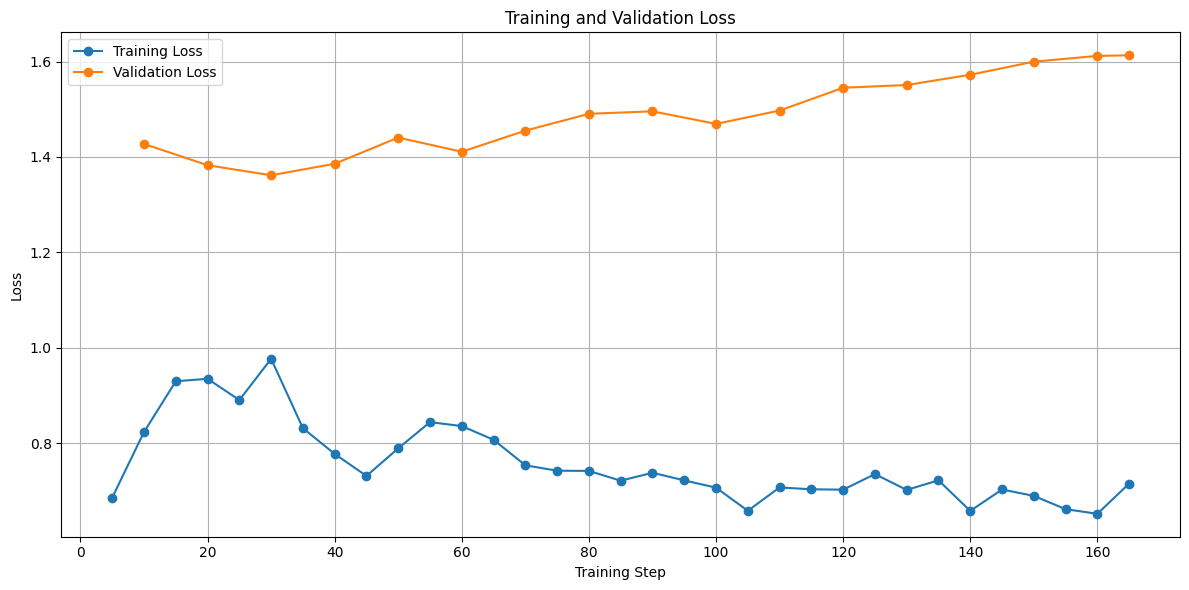

In [66]:
# ==========================================
# TRAINING LOSS vs EVALUATION LOSS
# ==========================================

import matplotlib.pyplot as plt

train_loss = history_df.dropna(subset=["loss"])
eval_loss_history = history_df.dropna(subset=["eval_loss"])

plt.figure(figsize=(12, 6))

plt.plot(
    train_loss["step"],
    train_loss["loss"],
    marker="o",
    label="Training Loss"
)

plt.plot(
    eval_loss_history["step"],
    eval_loss_history["eval_loss"],
    marker="o",
    label="Validation Loss"
)

plt.xlabel("Training Step")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
# Learning Rate

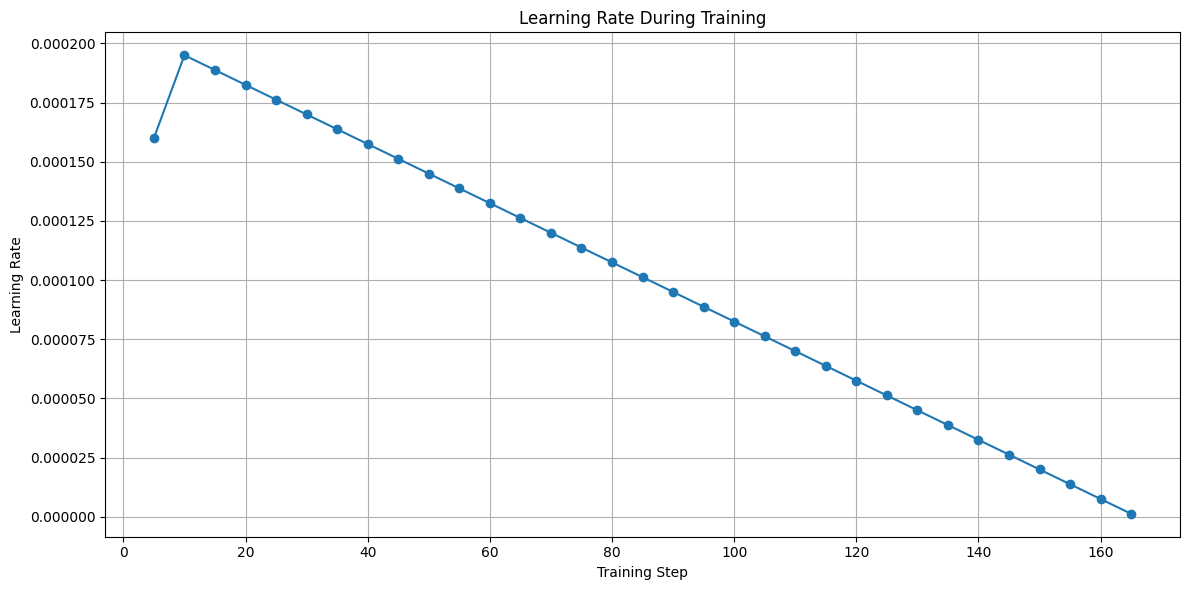

In [67]:
# ==========================================
# LEARNING RATE
# ==========================================

learning_rate = history_df.dropna(
    subset=["learning_rate"]
)

plt.figure(figsize=(12, 6))

plt.plot(
    learning_rate["step"],
    learning_rate["learning_rate"],
    marker="o"
)

plt.xlabel("Training Step")
plt.ylabel("Learning Rate")
plt.title("Learning Rate During Training")
plt.grid(True)
plt.tight_layout()
plt.show()

# Perplexity: Base vs Fine-tuned

Base perplexity      : 90.83
Fine-tuned perplexity: 3.45


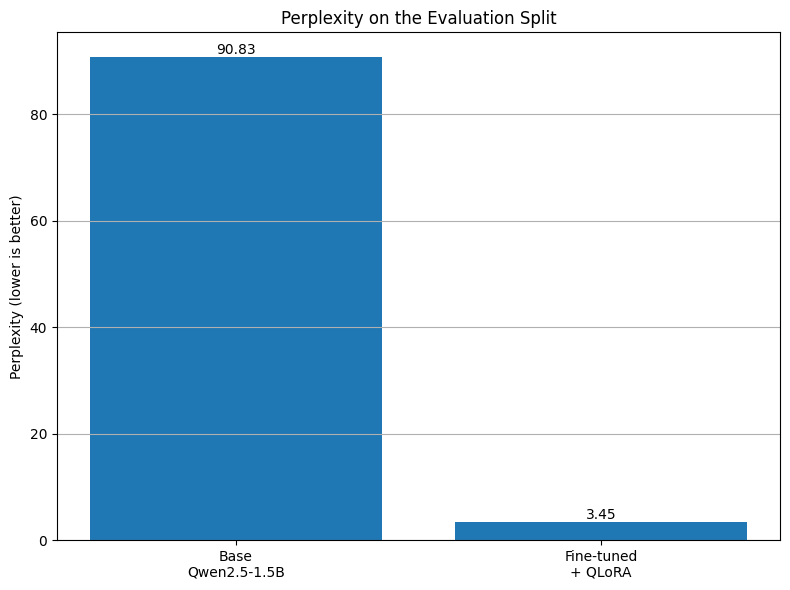

In [68]:
# ==========================================
# PERPLEXITY: BASE vs FINE-TUNED
# ==========================================

names = ["Base\nQwen2.5-1.5B", "Fine-tuned\n+ QLoRA"]
values = [metrics["base_perplexity"], metrics["fine_tuned_perplexity"]]

print(f"Base perplexity      : {values[0]:.2f}")
print(f"Fine-tuned perplexity: {values[1]:.2f}")

plt.figure(figsize=(8, 6))

bars = plt.bar(names, values)

for bar, value in zip(bars, values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{value:.2f}",
        ha="center",
        va="bottom"
    )

plt.ylabel("Perplexity (lower is better)")
plt.title("Perplexity on the Evaluation Split")
plt.grid(axis="y")
plt.tight_layout()
plt.show()


# Road Safety LLM Demo Application

In [69]:
# ============================================================
# Road Safety LLM QLoRA Fine-tuning - Demo Application
# ============================================================

# ------------------------------------------------------------
# 1. Install required packages
# ------------------------------------------------------------

!pip install -q -U "torchao>=0.16.0" transformers peft accelerate bitsandbytes gradio


# ------------------------------------------------------------
# 2. Imports
# ------------------------------------------------------------

import torch
import gradio as gr

from transformers import (
    AutoTokenizer,
    AutoModelForCausalLM,
)

from peft import PeftModel


# ------------------------------------------------------------
# 3. Configuration
# ------------------------------------------------------------

# Path to the fine-tuned LoRA adapter stored in Google Drive
MODEL_PATH = "/content/drive/MyDrive/road_safety_qwen2.5_1.5b_qlora/final_model"

# Base model used during QLoRA fine-tuning
BASE_MODEL = "Qwen/Qwen2.5-1.5B"

# Generation settings
MAX_NEW_TOKENS = 150


# ------------------------------------------------------------
# 4. Load tokenizer
# ------------------------------------------------------------

print("Loading tokenizer...")

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_PATH
)

# Stop on <|im_end|> (end of our training answers) or the normal EOS token
STOP_TOKEN_IDS = [
    tokenizer.convert_tokens_to_ids("<|im_end|>"),
    tokenizer.eos_token_id,
]


# ------------------------------------------------------------
# 5. Load base model
# ------------------------------------------------------------

print("Loading base model...")

base_model = AutoModelForCausalLM.from_pretrained(
    BASE_MODEL,
    dtype=torch.float16,
    device_map="auto",
)


# ------------------------------------------------------------
# 6. Load the fine-tuned LoRA adapter
# ------------------------------------------------------------

print("Loading fine-tuned LoRA adapter...")

model = PeftModel.from_pretrained(
    base_model,
    MODEL_PATH,
)

model.eval()

print("Model loaded successfully.")


# ------------------------------------------------------------
# 7. Generate response
# ------------------------------------------------------------

def generate_response(question):

    if not question.strip():
        return "Please enter a question."

    # Same chat format that was used for training (no system message)
    prompt = (
        "<|im_start|>user\n"
        f"{question.strip()}"
        "<|im_end|>\n"
        "<|im_start|>assistant\n"
    )

    inputs = tokenizer(
        prompt,
        return_tensors="pt"
    ).to(model.device)

    with torch.no_grad():

        outputs = model.generate(
            **inputs,
            max_new_tokens=MAX_NEW_TOKENS,
            do_sample=False,
            repetition_penalty=1.1,
            pad_token_id=tokenizer.eos_token_id,
            eos_token_id=STOP_TOKEN_IDS,
        )

    generated_tokens = outputs[0][inputs["input_ids"].shape[1]:]

    response = tokenizer.decode(
        generated_tokens,
        skip_special_tokens=True
    )

    return response.strip()


# ------------------------------------------------------------
# 8. Create the application
# ------------------------------------------------------------

demo = gr.Interface(
    fn=generate_response,
    inputs=gr.Textbox(
        label="Enter your question",
        placeholder="Example: Can I use a mobile phone while driving?",
        lines=4,
    ),
    outputs=gr.Textbox(
        label="Model Response",
        lines=10,
    ),
    title="Road Safety LLM - QLoRA Fine-tuned Model",
    description=(
        "Ask a question about Indian traffic rules and road safety and get a response "
        "from the QLoRA fine-tuned Qwen2.5-1.5B model. "
        "This is a small student project trained on about 200 short examples. "
        "Answers can be incomplete or wrong, so always check the official rules "
        "(Motor Vehicles Act) or the local traffic police."
    ),
    examples=[
        ["Can I use a mobile phone while driving?"],
        ["What should I do when approaching a pedestrian crossing?"],
        ["What are the consequences of violating traffic rules?"],
    ],
    cache_examples=False,
)


# ------------------------------------------------------------
# 9. Launch application
# ------------------------------------------------------------

demo.launch()

Loading tokenizer...
Loading base model...


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

Loading fine-tuned LoRA adapter...
Model loaded successfully.
It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://e095cbae137a395e54.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [70]:
# ==========================================
# FINAL RESULTS
# ==========================================

import json
import pandas as pd

project_path = "/content/drive/MyDrive/road_safety_qwen2.5_1.5b_qlora"

with open(f"{project_path}/evaluation_metrics.json", "r", encoding="utf-8") as f:
    metrics = json.load(f)

evaluation_df = pd.read_csv(f"{project_path}/model_evaluation.csv")

print("=" * 60)
print("DATASET")
print("=" * 60)
print("Train examples     :", metrics["train_examples"])
print("Validation examples:", metrics["validation_examples"])
print("Evaluation examples:", metrics["evaluation_examples"])
print("Max sequence length:", metrics["max_length"])
print("Epochs             :", metrics["epochs"])

print("\n" + "=" * 60)
print("EVALUATION LOSS AND PERPLEXITY (evaluation split)")
print("=" * 60)
print(f"Base model       : loss = {metrics['base_eval_loss']:.4f} | perplexity = {metrics['base_perplexity']:.2f}")
print(f"Fine-tuned model : loss = {metrics['fine_tuned_eval_loss']:.4f} | perplexity = {metrics['fine_tuned_perplexity']:.2f}")

print("\n" + "=" * 60)
print("LLM JUDGE (GPT-OSS 120B)")
print("=" * 60)
print("Questions judged:", len(evaluation_df))
print("Winner count:")
print(evaluation_df["better_model"].value_counts().to_string())
print(f"\nAverage overall score -> base: {evaluation_df['base_score'].mean():.2f} | "
      f"fine-tuned: {evaluation_df['fine_tuned_score'].mean():.2f}")

print("\n" + "=" * 60)
print("SAVED FILES (Google Drive)")
print("=" * 60)
print(project_path)
print(" - indian-traffic-law/            (train / validation / evaluation splits)")
print(" - indian-traffic-law-formatted/  (chat-formatted text)")
print(" - indian-traffic-law-tokenized/  (tokenized data)")
print(" - checkpoints/                   (training checkpoints)")
print(" - final_model/                   (final LoRA adapter + tokenizer)")
print(" - evaluation_metrics.json")
print(" - model_comparison.csv")
print(" - model_evaluation.csv")

DATASET
Train examples     : 129
Validation examples: 16
Evaluation examples: 17
Max sequence length: 63
Epochs             : 1

EVALUATION LOSS AND PERPLEXITY (evaluation split)
Base model       : loss = 4.5090 | perplexity = 90.83
Fine-tuned model : loss = 1.2387 | perplexity = 3.45

LLM JUDGE (GPT-OSS 120B)
Questions judged: 8
Winner count:
better_model
fine_tuned    7
tie           1

Average overall score -> base: 1.12 | fine-tuned: 4.00

SAVED FILES (Google Drive)
/content/drive/MyDrive/road_safety_qwen2.5_1.5b_qlora
 - indian-traffic-law/            (train / validation / evaluation splits)
 - indian-traffic-law-formatted/  (chat-formatted text)
 - indian-traffic-law-tokenized/  (tokenized data)
 - checkpoints/                   (training checkpoints)
 - final_model/                   (final LoRA adapter + tokenizer)
 - evaluation_metrics.json
 - model_comparison.csv
 - model_evaluation.csv
